In [10]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict
from dotenv import load_dotenv
import os
from langchain_groq import ChatGroq

In [11]:
my_secret_key = os.getenv("GROQ_API_KEY")
load_dotenv()
llm = ChatGroq(
    model="openai/gpt-oss-20b",  # Current standard for high-accuracy reasoning workflows
    api_key=my_secret_key,
    temperature=0.7
)

In [12]:
# define the state
class BlogLLM(TypedDict):
    topic : str
    outline : str
    content : str

In [13]:
def create_blog(state:BlogLLM)->BlogLLM:
    #extract topic from the state 
    topic = state['topic']
    # extract outline from the state
    outline = state['outline']
    
    # form prompt 
    prompt = f'Write a detailed blog on the topic - {topic} using the follwing outline \n {outline}'
    
    #model 
    content = llm.invoke(prompt).content
    
    state['content'] = content 
    
    return state

In [14]:
def create_outline(state:BlogLLM)->BlogLLM:
    #extract topic from the state 
    topic = state['topic']
    
    # form prompt 
    prompt = f'Generate a detailed outline for a blog on the topic - {topic}'
    
    #model 
    outline = llm.invoke(prompt).content
    
    state['outline'] = outline 
    
    return state

In [15]:
# define the graph
graph = StateGraph(BlogLLM)

# add nodes
graph.add_node('create_blog',create_blog)
graph.add_node('create_outline',create_outline)
# add edges

graph.add_edge(START,'create_outline')
graph.add_edge('create_outline','create_blog')
graph.add_edge('create_blog',END)

#compile graph
workflow = graph.compile()



In [16]:
# Execute the graph
intial_state = {
    'topic' : 'Rise of AI in India'
}

final_state = workflow.invoke(intial_state)

print(final_state['content'])

# Rise of AI in India – From Research Labs to the Marketplace  

---

## 1. Hook & Thesis  

> **“India’s AI market is projected to hit $25 bn by 2027, up 30% YoY.”**  
> That headline isn’t just a number—it’s a signal that India is no longer a passive player in the global AI race.  

India is transitioning from a talent‑rich but under‑leveraged ecosystem to a global AI powerhouse. The momentum is powered by a confluence of **policy direction, private‑sector dynamism, and a data economy that is rapidly expanding**. This blog unpacks how that shift is unfolding, what it means for the country’s economy, and why the next decade will be a defining era for AI in India.

---

## 2. Historical Context  

| Era | Key Milestones | Impact |
|-----|----------------|--------|
| **1970s‑80s** | Early AI research at IITs & BARC | Laid the academic foundations; first AI labs in India. |
| **1990s** | First AI conferences, DARPA‑style funding | Brought global visibility; Indian researchers began publi

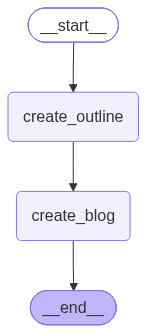

In [17]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())

In [18]:
print(final_state)

{'topic': 'Rise of AI in India', 'outline': '# Outline for a Blog Post  \n**Title:** *Rise of AI in India – From Research Labs to the Marketplace*  \n\n---\n\n## 1. Hook & Thesis  \n- **Opening anecdote or statistic** – e.g., “India’s AI market is projected to hit $25\u202fbn by 2027, up 30% YoY.”  \n- **Thesis statement** – India is transitioning from a talent‑rich but under‑leveraged AI ecosystem to a global player, driven by policy, private innovation, and a burgeoning data economy.  \n\n---\n\n## 2. Historical Context  \n| Era | Key Milestones | Impact |\n|-----|----------------|--------|\n| 1970s‑80s | Early AI research at IITs & BARC | Foundation for academic AI |\n| 1990s | First AI conferences, DARPA‑style funding | Global visibility |\n| 2000s | Rise of data‑driven startups (e.g., Infosys Nia) | Shift to commercial AI |\n| 2010s | Government AI initiatives (e.g., AI for All) | Policy push |\n\n*Include a brief timeline infographic suggestion.*\n\n---\n\n## 3. Current AI Landsc

In [19]:
print(final_state['outline'])

# Outline for a Blog Post  
**Title:** *Rise of AI in India – From Research Labs to the Marketplace*  

---

## 1. Hook & Thesis  
- **Opening anecdote or statistic** – e.g., “India’s AI market is projected to hit $25 bn by 2027, up 30% YoY.”  
- **Thesis statement** – India is transitioning from a talent‑rich but under‑leveraged AI ecosystem to a global player, driven by policy, private innovation, and a burgeoning data economy.  

---

## 2. Historical Context  
| Era | Key Milestones | Impact |
|-----|----------------|--------|
| 1970s‑80s | Early AI research at IITs & BARC | Foundation for academic AI |
| 1990s | First AI conferences, DARPA‑style funding | Global visibility |
| 2000s | Rise of data‑driven startups (e.g., Infosys Nia) | Shift to commercial AI |
| 2010s | Government AI initiatives (e.g., AI for All) | Policy push |

*Include a brief timeline infographic suggestion.*

---

## 3. Current AI Landscape  

### 3.1 Ecosystem Overview  
- **Startups** – > 3,000 AI‑focused s